In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
# Load the Training_Data sheet from the Excel file
df = pd.read_excel("/content/Data_User_Modeling_Dataset_Hamdi Tolga KAHRAMAN.xls", sheet_name="Training_Data")
print("Dataset loaded successfully from Training_Data sheet.")
df.head()

Dataset loaded successfully from Training_Data sheet.


,STG,SCG,STR,LPR,PEG,UNS,Unnamed: 6,Unnamed: 7,Attribute Information:
0,0.00,0.00,0.00,0.00,0.00,very_low,NaN,NaN,STG (The degree of study time for goal object ...
1,0.08,0.08,0.10,0.24,0.90,High,NaN,NaN,SCG (The degree of repetition number of user f...
2,0.06,0.06,0.05,0.25,0.33,Low,NaN,NaN,STR (The degree of study time of user for rela...
3,0.10,0.10,0.15,0.65,0.30,Middle,NaN,NaN,LPR (The exam performance of user for related ...
4,0.08,0.08,0.08,0.98,0.24,Low,NaN,NaN,PEG (The exam performance of user for goal obj...


In [ ]:
# 1. Clean the dataset by selecting only the core feature columns
feature_cols = ['STG', 'SCG', 'STR', 'LPR', 'PEG']
X_raw = df[feature_cols].copy()

# 2. Drop any rows that are completely empty if they exist in the spreadsheet
X_raw = X_raw.dropna()

# 3. Standardize the features for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Convert scaled array back to DataFrame for clean visualization
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

print("Cleaned and scaled dataset shape:", X_scaled_df.shape)
X_scaled_df.head()

Cleaned and scaled dataset shape: (258, 5)


,STG,SCG,STR,LPR,PEG
0,-1.768519,-1.681269,-1.906619,-1.747441,-1.800197
1,-1.387319,-1.303110,-1.499225,-0.778241,1.733152
2,-1.482619,-1.397650,-1.702922,-0.737857,-0.504636
3,-1.292019,-1.208570,-1.295528,0.877477,-0.622414
4,-1.387319,-1.303110,-1.580704,2.210128,-0.857971


In [ ]:
# Evaluate Agglomerative Clustering for different cluster numbers (K)
results = []

for k in range(2, 7):
    # Initialize Agglomerative Clustering with Ward linkage
    agg_model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = agg_model.fit_predict(X_scaled)

    # Calculate metrics
    sil_score = silhouette_score(X_scaled, labels)
    db_index = davies_bouldin_score(X_scaled, labels)

    results.append({
        'Clusters (K)': k,
        'Silhouette Score': round(sil_score, 4),
        'Davies-Bouldin Index': round(db_index, 4)
    })

# Present evaluation results
eval_df = pd.DataFrame(results)
print("=== Agglomerative Clustering Evaluation ===")
print(eval_df.to_string(index=False))

# Fit the final recommended 4-cluster model and save the labels to our original dataframe
best_k = 4
final_model = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
X_raw['Cluster'] = final_model.fit_predict(X_scaled)
print(f"\nSuccessfully assigned {best_k} cluster labels to the dataset.")
X_raw.head()

=== Agglomerative Clustering Evaluation ===
 Clusters (K)  Silhouette Score  Davies-Bouldin Index
            2            0.1384                2.0767
            3            0.1463                2.0479
            4            0.1665                1.6596
            5            0.1709                1.5382
            6            0.1448                1.5051

Successfully assigned 4 cluster labels to the dataset.


,STG,SCG,STR,LPR,PEG,Cluster
0,0.00,0.00,0.00,0.00,0.00,1
1,0.08,0.08,0.10,0.24,0.90,0
2,0.06,0.06,0.05,0.25,0.33,1
3,0.10,0.10,0.15,0.65,0.30,1
4,0.08,0.08,0.08,0.98,0.24,1


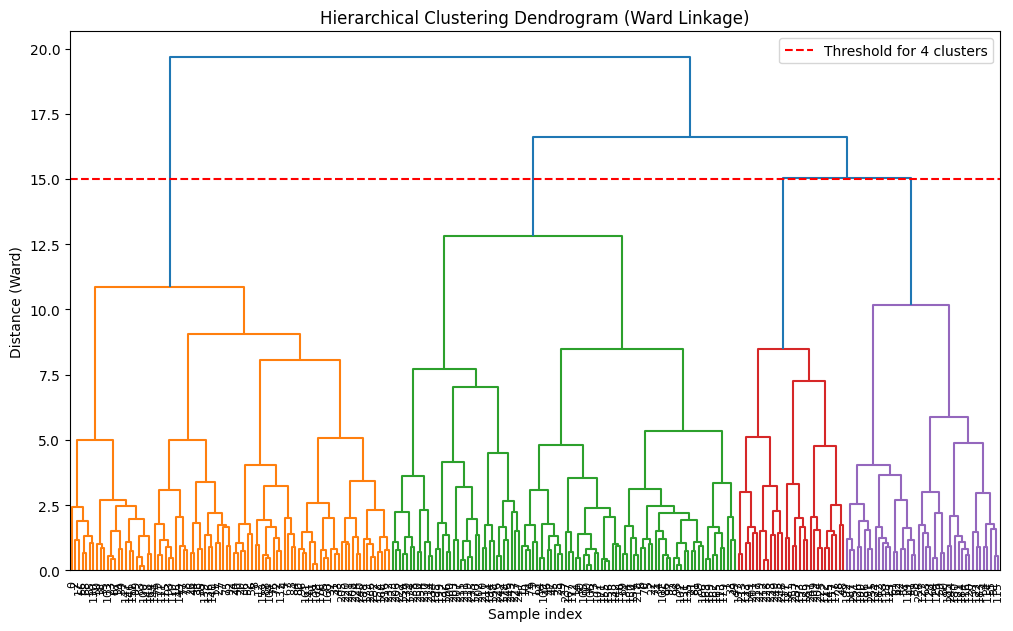

In [ ]:
# Generate the linkage matrix for hierarchical clustering
# Using 'ward' linkage as it minimizes the variance of clusters being merged
Z = linkage(X_scaled, method='ward')

# Plot the dendrogram
plt.figure(figsize=(12, 7))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Sample index")
plt.ylabel("Distance (Ward)")
dendrogram(
    Z,
    leaf_rotation=90.,  # rotates the x-axis labels
    leaf_font_size=8.,  # font size for the x-axis labels
)
plt.axhline(y=15, color='r', linestyle='--', label='Threshold for 4 clusters')
plt.legend()
plt.show()